In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

In [2]:
DATASET_PATH = r'D:\Plant_Disease_Classifier\dataset\raw\Plant_Disease_Detection'

In [3]:
classes = sorted([
    folder for folder in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH,folder))
])
print("Classes: ",len(classes))
print("\n Classes: ")
for i ,class_name in enumerate(classes):
    print(f"{i}, {class_name}")

Classes:  23

 Classes: 
0, Apple___Apple_scab
1, Apple___Black_rot
2, Apple___Cedar_apple_rust
3, Apple___healthy
4, Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
5, Corn_(maize)___Common_rust_
6, Corn_(maize)___Northern_Leaf_Blight
7, Corn_(maize)___healthy
8, Pepper__bell___Bacterial_spot
9, Pepper__bell___healthy
10, Potato___Early_blight
11, Potato___Late_blight
12, Potato___healthy
13, Tomato_Bacterial_spot
14, Tomato_Early_blight
15, Tomato_Late_blight
16, Tomato_Leaf_Mold
17, Tomato_Septoria_leaf_spot
18, Tomato_Spider_mites_Two_spotted_spider_mite
19, Tomato__Target_Spot
20, Tomato__Tomato_YellowLeaf__Curl_Virus
21, Tomato__Tomato_mosaic_virus
22, Tomato_healthy


In [4]:
class_counts = {}
for class_name in classes:
    class_path = os.path.join(DATASET_PATH, class_name)
    images = [file for file in os.listdir(class_path) if file.lower().endswith((".jpg",'.jpeg',".png"))]
    class_counts[class_name] = len(images)
class_counts

{'Apple___Apple_scab': 2016,
 'Apple___Black_rot': 1987,
 'Apple___Cedar_apple_rust': 1760,
 'Apple___healthy': 2008,
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': 1642,
 'Corn_(maize)___Common_rust_': 1907,
 'Corn_(maize)___Northern_Leaf_Blight': 1908,
 'Corn_(maize)___healthy': 1859,
 'Pepper__bell___Bacterial_spot': 997,
 'Pepper__bell___healthy': 1478,
 'Potato___Early_blight': 1000,
 'Potato___Late_blight': 1000,
 'Potato___healthy': 152,
 'Tomato_Bacterial_spot': 2127,
 'Tomato_Early_blight': 1000,
 'Tomato_Late_blight': 1909,
 'Tomato_Leaf_Mold': 952,
 'Tomato_Septoria_leaf_spot': 1771,
 'Tomato_Spider_mites_Two_spotted_spider_mite': 1676,
 'Tomato__Target_Spot': 1404,
 'Tomato__Tomato_YellowLeaf__Curl_Virus': 3208,
 'Tomato__Tomato_mosaic_virus': 373,
 'Tomato_healthy': 1591}

In [5]:
df = pd.DataFrame(list(class_counts.items()),columns=['Class','Count'])
df = df.sort_values('Count',ascending = False)
df

,Class,Count
20,Tomato__Tomato_YellowLeaf__Curl_Virus,3208
13,Tomato_Bacterial_spot,2127
0,Apple___Apple_scab,2016
3,Apple___healthy,2008
1,Apple___Black_rot,1987
15,Tomato_Late_blight,1909
6,Corn_(maize)___Northern_Leaf_Blight,1908
5,Corn_(maize)___Common_rust_,1907
7,Corn_(maize)___healthy,1859
17,Tomato_Septoria_leaf_spot,1771


In [6]:
total_images = df['Count'].sum()
print("Total Images: ",total_images)
print("Number of Classes: ",len(classes))
print("Average images per classes: ",round(total_images/len(classes),2))
print("Minimum images in a class: ",df['Count'].min())
print("Maximum image in a class: ",df['Count'].max())

Total Images:  35725
Number of Classes:  23
Average images per classes:  1553.26
Minimum images in a class:  152
Maximum image in a class:  3208


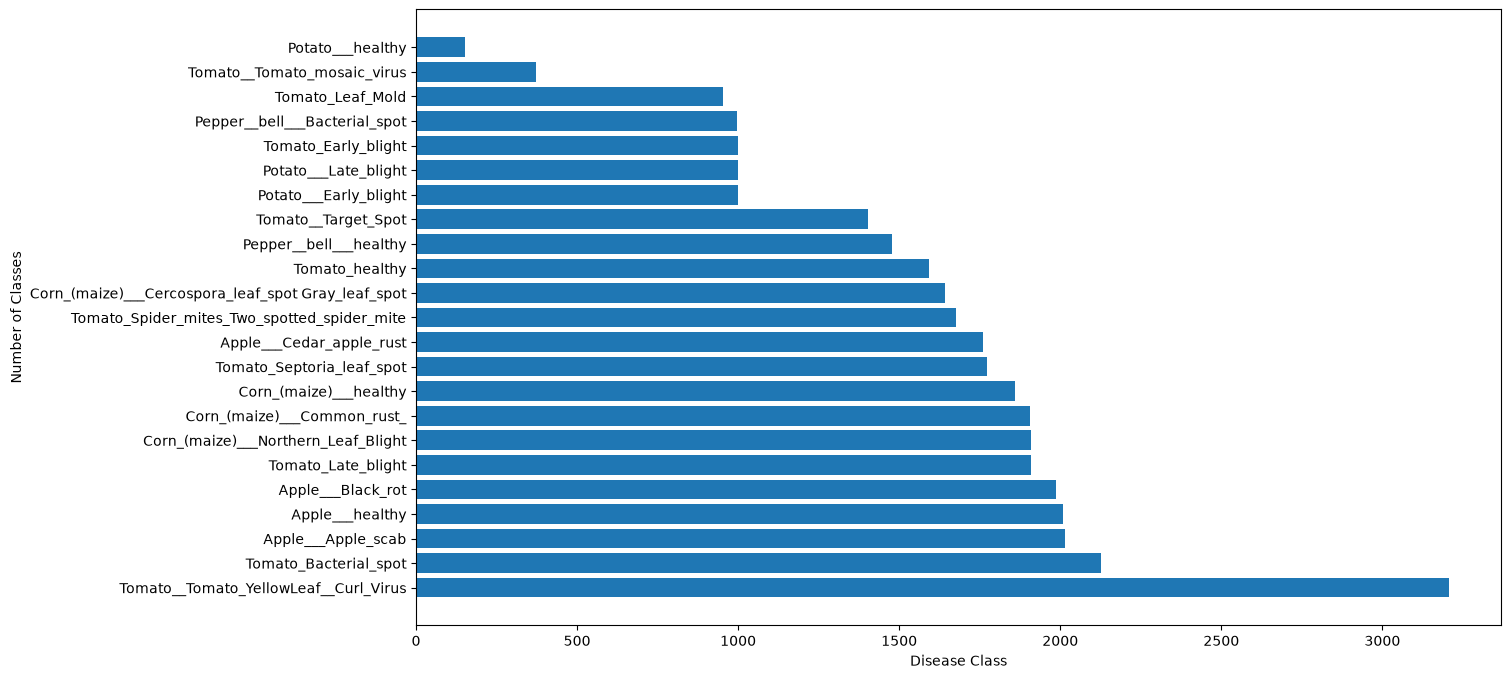

In [7]:
plt.figure(figsize = (14,8))
plt.barh(df['Class'],df['Count'])
plt.xlabel("Disease Class")
plt.ylabel("Number of Classes")
plt.show()

In [8]:
dimension = []
for class_name in classes:
    class_path = os.path.join(DATASET_PATH,class_name)
    for file_name in os.listdir(class_path):
        if file_name.lower().endswith(('.jpg','.jpeg','.png')):
            file_path = os.path.join(class_path,file_name)
            try:
                with Image.open(file_path) as img:
                    dimension.append(img.size)
            except Exception as e:
                pass

In [9]:
dimension_count = Counter(dimension)
print("Number of unique dimensions: ",len(dimension_count))
for dimension,count in dimension_count.most_common(10):
    print(f"{dimension}: {count}")

Number of unique dimensions:  1
(256, 256): 35725


In [11]:
corrupted_images = []
for class_name in classes:
    class_path = os.path.join(DATASET_PATH,class_name)
    for file_name in os.listdir(class_path):
        if file_name.lower().endswith(('.jpg','.jpeg','.png')):
            file_path = os.path.join(class_path,file_name)
            try:
                with Image.open(file_path) as img:
                    img.verify()
            except Exception as e:
                corrupted_images.append(file_path)
print("Corrupted Images: ",len(corrupted_images))

Corrupted Images:  0


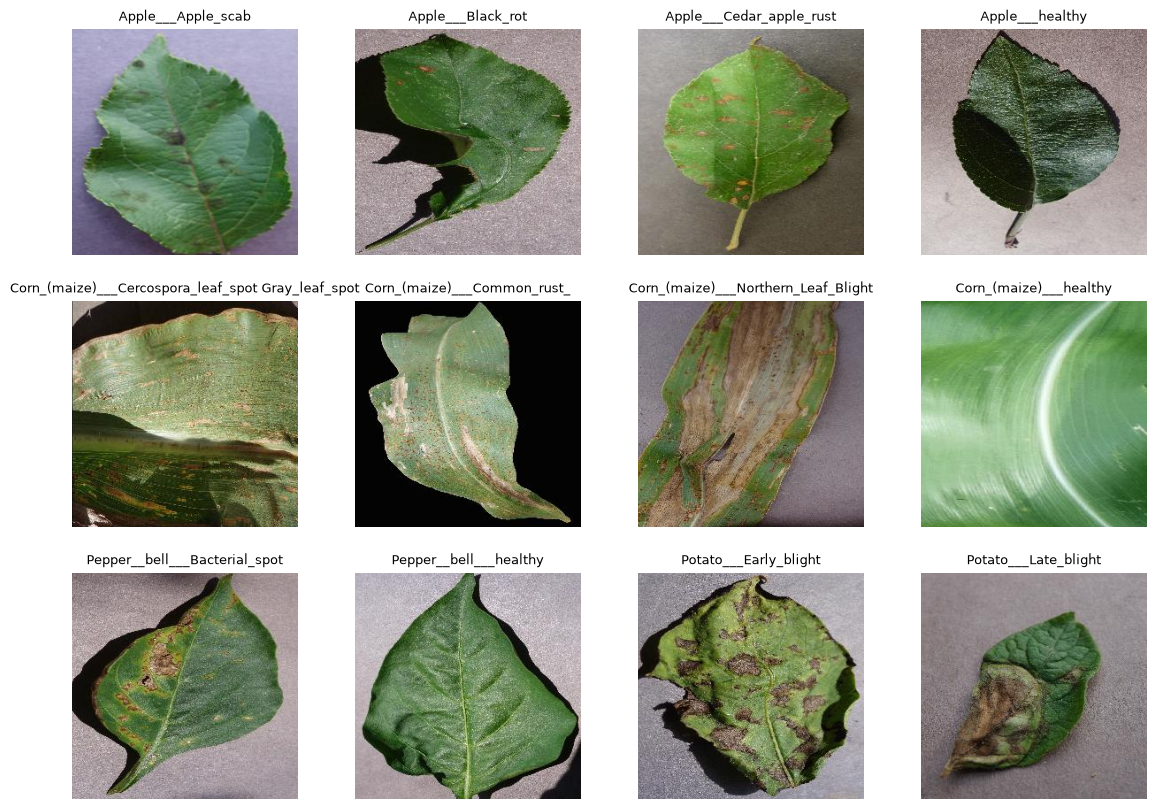

In [12]:
fig,axes = plt.subplots(3,4,figsize = (14,10))
for ax,class_name in zip(axes.flat,classes[:12]):
    class_path = os.path.join(DATASET_PATH,class_name)
    image_files = [
        f for f in os.listdir(class_path) if f.lower().endswith(('.jpg','.jpeg','.png'))
    ]
    image_path = os.path.join(class_path,image_files[0])
    image = Image.open(image_path)
    ax.imshow(image)
    ax.set_title(class_name,fontsize = 9)
    ax.axis('off')
plt.show()

In [14]:
import hashlib
hashes = {}
duplicates = []
for class_name in classes:
    class_path = os.path.join(DATASET_PATH,class_name)
    for file_name in os.listdir(class_path):
        if not file_name.lower().endswith(('.jpg','.jpeg','.png')):
            continue
        file_path = os.path.join(class_path,file_name)
        try:
            with open(file_path,'rb') as f:
                        
                        file_hash = hashlib.md5(f.read()).hexdigest()
                        if file_hash in hashes:
                            duplicates.append((file_path,file_hash))
                        else:
                            hashes[file_hash] = file_path
        except Exception as e:
            print("Error in file: ",file_path,e)
print("Total Images checked: ",len(hashes))
print("Total Duplicates found: ",len(duplicates))

Total Images checked:  35703
Total Duplicates found:  22
